## Calculating the phonon dispersion and density of states of $GaAs$

Run all cells to calculate the phonon dispersion and phonon density of states of $GaAs$ using quantum-espresso based on the tutorial at https://pranabdas.github.io/espresso/hands-on/phonon

1. Load in modules
2. Plotting updates function
3. Phonon Dispersion
    1. SCF Calculation
    2. Dynamical Matrix Calculation (in parallel)
    3. Real-Space Force Constants
    4. Phonon Frequencies Along the Band Path
    5. Plotting the Phonon Dispersion
4. Phonon Density of States
    1. Phonon DOS Calculation
    2. Plotting the Phonon DOS

**Changes from the tutorial to cut the run time:**

- The q-grid is 4×4×4 (8 q-points) instead of 6×6×6 (16 q-points).
- Each q-point is a separate `ph.x` run, and up to `PH_WORKERS` of them run at once. This doesn't change the results, because the q-points are independent.

The other settings match the tutorial.

**Resuming:** if section 3.2 is interrupted, set `RECOVER = True` in section 1 and run all cells again. This skips the SCF step and any finished q-points, and restarts the unfinished ones from where they stopped.

## 1. Load in modules

In [1]:
# Modules + QE setup for the GaAs phonon workflow:
#   pw.x scf -> parallel ph.x on a q-grid -> q2r.x -> matdyn.x (dispersion, then DOS) -> plot
import math, os, re, shutil, subprocess, time, urllib.request   # run QE executables, fetch pseudopotentials
from pathlib import Path
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

RECOVER = False                                  # True resumes an interrupted ph.x run (see the top of this notebook)
NQ = 4                                           # q-grid is NQ x NQ x NQ (the tutorial uses 6)
PH_WORKERS = 6                                   # ph.x runs at once: one per physical core of the Ryzen 5600X

ROOT = Path.cwd()
QE_BIN = ROOT / "qe" / "bin"                     # native Windows build (see build_qe.sh)
PSEUDO_DIR = ROOT / "pseudo"
RUNS = ROOT / "runs"
GAAS_RUN = RUNS / "ph_gaas_parallel"
GAAS_RUN.mkdir(parents=True, exist_ok=True)
PSEUDO_DIR.mkdir(exist_ok=True)

os.environ["PATH"] = str(QE_BIN) + os.pathsep + os.environ["PATH"]   # bundled MinGW DLLs live here too
# One thread is far faster for small cells on this build (Si SCF: 2.5 s on 1 thread, about 190 s on 12)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ.setdefault("OMP_STACKSIZE", "256M")   # OpenMP threads overflow the default Windows stack
os.environ.setdefault("ESPRESSO_PSEUDO", str(PSEUDO_DIR))

PW = shutil.which("pw.x.exe", path=str(QE_BIN))
PH = shutil.which("ph.x.exe", path=str(QE_BIN))
Q2R = shutil.which("q2r.x.exe", path=str(QE_BIN))
MATDYN = shutil.which("matdyn.x.exe", path=str(QE_BIN))
assert PW and PH and Q2R and MATDYN, f"pw.x / ph.x / q2r.x / matdyn.x not found in {QE_BIN}"

# The tutorial's own copies: the As file isn't on the QE site, and the QE site's Ga file is a newer generation
GA_PSEUDO = "Ga.pbe-dn-kjpaw_psl.1.0.0.UPF"
AS_PSEUDO = "As.nc.z_15.oncvpsp3.dojo.v4-std.upf"
for pseudo in (GA_PSEUDO, AS_PSEUDO):
    if not (PSEUDO_DIR / pseudo).exists():
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/pranabdas/espresso/main/src/pseudos/{pseudo}", PSEUDO_DIR / pseudo)

def run_qe(exe, inp: Path, out: Path | None = None):
    """Run a QE executable on `inp` inside its folder, write stdout to `out` (default: .in -> .out)."""
    inp = Path(inp)
    out = Path(out) if out else inp.with_suffix(".out")
    with open(inp) as fin, open(out, "w") as fout:
        res = subprocess.run([exe], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
    if res.returncode != 0 or "JOB DONE" not in out.read_text(errors="ignore"):
        raise RuntimeError(f"{Path(exe).name} failed on {inp.name} - see {out}")
    return out

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f" - {detail}" if detail else ""))

print("pw.x    :", PW)
print("ph.x    :", PH)
print("q2r.x   :", Q2R)
print("matdyn.x:", MATDYN)
for pseudo in (GA_PSEUDO, AS_PSEUDO):
    check("Pseudopotential available", "PP_HEADER" in (PSEUDO_DIR / pseudo).read_text(errors="ignore"), pseudo)

pw.x    : C:\Users\Caesium\Desktop\qe_exp\qe\bin\pw.x.exe
ph.x    : C:\Users\Caesium\Desktop\qe_exp\qe\bin\ph.x.exe
q2r.x   : C:\Users\Caesium\Desktop\qe_exp\qe\bin\q2r.x.exe
matdyn.x: C:\Users\Caesium\Desktop\qe_exp\qe\bin\matdyn.x.exe
[PASS] Pseudopotential available - Ga.pbe-dn-kjpaw_psl.1.0.0.UPF
[PASS] Pseudopotential available - As.nc.z_15.oncvpsp3.dojo.v4-std.upf


## 2. Plotting updates function

Both calculations in this notebook redraw a plot while they run, so you can see how close they are to finishing. They then check the result and stop the notebook if the run failed. Stopping the cell also stops the programs.

- **SCF (`run_pw`):** accuracy per iteration against `conv_thr`.
- **Phonons (`run_ph_parallel`):** irreducible representations finished for each q-point, and in total. It starts the q-points with the most representations first, and starts another whenever one finishes.

The time left for `ph.x` is a rough estimate: it assumes the remaining representations take as long as the finished ones.

In [2]:
# Live monitor: QE writes to its .out file as it runs, so we re-read that file and redraw
# one figure in place:
#   scf -> accuracy against conv_thr, per iteration
#   ph  -> representations finished for each q-point, and in total
BLUE = "#2a78d6"
INK, MUTED, GRID, TRACK, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#f0efec", "#fcfcfb"
NUMBER = r"([0-9.]+(?:[Ee][+-]?[0-9]+)?)"

def read_setting(settings, name, default):
    """Read a number from a QE input. \b stops conv_thr also matching etot_conv_thr."""
    found = re.search(rf"\b{name}\s*=\s*([0-9.eEdD+-]+)", settings)
    return float(found.group(1).lower().replace("d", "e")) if found else default

def read_scf_progress(text):
    """Pull the convergence numbers out of a pw.x output, finished or not."""
    text = text[:text.rfind("\n") + 1]                 # ignore a half-written last line
    return {
        "iteration": len(re.findall(r"iteration #\s*\d+", text)),
        "accuracy": [max(float(a), 1e-30) for a in re.findall(rf"estimated scf accuracy\s+<\s+{NUMBER}", text)],
        "energy": [float(e) for e in re.findall(r"total energy\s+=\s+(-?[0-9.]+) Ry", text)],
        "clock": [float(t) for t in re.findall(r"total cpu time spent up to now is\s+([0-9.]+)", text)],
        "done": "JOB DONE" in text,
    }

def read_q_progress(text):
    """Count the representations a ph.x run has finished, including any a resumed run lists as done."""
    return len(re.findall(r"Convergence has been achieved", text)) + len(re.findall(r"modes?\s*-\s*Done", text))

def scf_estimate(p, conv_thr):
    """Return (fraction of the way to conv_thr on a log scale, seconds left or None)."""
    acc = p["accuracy"]
    if p["done"] or (acc and acc[-1] < conv_thr):
        return 1.0, 0.0
    if not acc:
        return 0.0, None
    fraction = math.log(acc[0] / acc[-1]) / math.log(acc[0] / conv_thr)
    fraction = min(max(fraction, 0.0), 0.99)
    if len(acc) < 2 or len(p["clock"]) < 3:
        return fraction, None
    logs = np.log10(acc[-3:])
    slope = np.polyfit(range(len(logs)), logs, 1)[0]
    if slope >= 0:                                     # not improving, so no honest estimate
        return fraction, None
    steps_left = math.ceil((math.log10(conv_thr) - logs[-1]) / slope)
    return fraction, steps_left * float(np.mean(np.diff(p["clock"])[-3:]))

def as_time(seconds):
    if seconds < 90:
        return f"{seconds:.0f} s"
    return f"{seconds / 60:.1f} min" if seconds < 5400 else f"{seconds / 3600:.1f} h"

def style(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    ax.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)

def target_line(ax, y, label):
    ax.axhline(y, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
    ax.annotate(label, (1, y), xycoords=("axes fraction", "data"), xytext=(0, 4),
                textcoords="offset points", ha="right", fontsize=8, color=MUTED)

def count_axis(ax, count):
    ax.set_xlim(0.5, max(count + 1.5, 6))
    ax.xaxis.get_major_locator().set_params(integer=True)

def draw_scf(left, right, p, conv_thr):
    acc = p["accuracy"]
    style(left, "SCF accuracy", "Iteration", "Estimated accuracy (Ry)")
    left.set_yscale("log")
    left.set_ylim(conv_thr / 5, 1)
    target_line(left, conv_thr, f"target {conv_thr:.0e} Ry")
    if acc:
        left.plot(range(1, len(acc) + 1), acc, color=BLUE, linewidth=2, marker="o", markersize=5)
        left.set_ylim(min(min(acc), conv_thr) / 5, max(acc) * 5)
    count_axis(left, len(acc))

    style(right, "Energy change per iteration", "Iteration", "|ΔE| (Ry)")
    right.set_yscale("log")
    right.set_ylim(1e-9, 1)
    change = np.abs(np.diff(p["energy"]))
    if change.size:
        change = np.maximum(change, 1e-12)
        right.plot(range(2, change.size + 2), change, color=BLUE, linewidth=2, marker="o", markersize=5)
        right.set_ylim(change.min() / 5, change.max() * 5)
    count_axis(right, len(acc))

def draw_title(fig, bar, label, state, detail, fraction):
    fig.text(0.08, 0.93, f"{label}: {state}", fontsize=12, color=INK, weight="bold")
    fig.text(0.98, 0.93, detail, fontsize=9, color=MUTED, ha="right")
    bar.barh(0, 1, color=TRACK, height=1)
    bar.barh(0, fraction, color=BLUE, height=1)
    bar.set_xlim(0, 1)
    bar.axis("off")

def new_layout(fig):
    fig.clf()
    grid = fig.add_gridspec(2, 2, height_ratios=[0.05, 1], hspace=0.42, wspace=0.26,
                            left=0.08, right=0.98, top=0.84, bottom=0.14)
    return fig.add_subplot(grid[0, :]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])

def draw_pw(fig, text, conv_thr, elapsed, finished, failed):
    bar, left, right = new_layout(fig)
    p = read_scf_progress(text)
    fraction, seconds = scf_estimate(p, conv_thr)
    draw_scf(left, right, p, conv_thr)
    detail = f"iteration {p['iteration']}"
    if p["accuracy"]:
        detail += f"  ·  accuracy {p['accuracy'][-1]:.1e} Ry"
    state = f"{fraction:.0%}  ·  " + (f"about {as_time(seconds)} left" if seconds is not None else "estimating time left")
    if failed:
        state = f"Stopped before finishing after {as_time(elapsed)}"
    elif finished:
        state, fraction = f"Finished in {as_time(elapsed)}", 1.0
    draw_title(fig, bar, "SCF", state, detail, fraction)

def draw_ph(fig, irreps, done, status, history, elapsed, finished, failed):
    bar, left, right = new_layout(fig)
    total, count = sum(irreps.values()), sum(done.values())

    style(left, "Each q-point", "Representations", "")
    left.grid(False)
    rows = sorted(irreps)
    for row, n in enumerate(rows):
        left.barh(row, irreps[n], color=TRACK, height=0.7)
        left.barh(row, done[n], color=BLUE, height=0.7)
        left.annotate(status[n], (irreps[n], row), xytext=(4, 0), textcoords="offset points",
                      va="center", fontsize=8, color=MUTED)
    left.set_yticks(range(len(rows)), labels=[f"q{n}" for n in rows])
    left.invert_yaxis()
    left.set_xlim(0, max(irreps.values()) * 1.35)

    style(right, "All q-points", "Run time (min)", "Representations")
    right.axhline(total, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
    right.annotate(f"total {total}", (0, total), xycoords=("axes fraction", "data"),
                   xytext=(4, -11), textcoords="offset points", fontsize=8, color=MUTED)
    right.set_ylim(0, total * 1.08)
    if history:
        right.plot([h[0] / 60 for h in history], [h[1] for h in history], color=BLUE, linewidth=2)

    fraction = count / total
    gained = count - history[0][1] if history else 0
    if failed:
        state = f"Stopped before finishing after {as_time(elapsed)}"
    elif finished:
        state, fraction = f"Finished in {as_time(elapsed)}", 1.0
    elif gained:
        state = f"{fraction:.0%}  ·  about {as_time((total - count) * elapsed / gained)} left"
    else:
        state = f"{fraction:.0%}  ·  estimating time left"
    running = sum(s == "running" for s in status.values())
    draw_title(fig, bar, "PH", state, f"{running} running  ·  {count} of {total} representations", fraction)

def live_figure():
    fig = plt.figure(figsize=(10, 4.2), dpi=110, facecolor=SURFACE)
    plt.close(fig)                                     # stops a second copy appearing at the end
    return fig, display(fig, display_id=True)

def stop_with_error(name, output):
    """Stop here so later steps don't run on bad data."""
    message = re.search(r"%{20,}\n(.*?)\n\s*%{20,}", output, re.S)
    raise RuntimeError(f"{name} failed: {' '.join(message.group(1).split()) if message else 'see its .out file'}")

def run_pw(name, text, run_dir, refresh=1.0):
    """Write the input file `name` in `run_dir`, run pw.x with the live plot, check it, and return its output."""
    inp = Path(run_dir) / name
    out = inp.with_suffix(".out")
    inp.write_text(text)
    conv_thr = read_setting(text, "conv_thr", 1e-6)
    fig, handle = live_figure()

    started = time.time()
    def redraw(finished=False, failed=False):
        draw_pw(fig, out.read_text(errors="ignore") if out.exists() else "", conv_thr, time.time() - started, finished, failed)
        handle.update(fig)

    with open(inp) as fin, open(out, "w") as fout:
        proc = subprocess.Popen([PW], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
        try:
            while proc.poll() is None:
                redraw()
                time.sleep(refresh)
        except BaseException:                          # e.g. the stop button: don't leave pw.x running
            proc.kill()
            proc.wait()
            redraw(failed=True)
            raise
    output = out.read_text(errors="ignore")
    results = [proc.returncode == 0, "JOB DONE" in output, "convergence has been achieved" in output]
    redraw(finished=all(results), failed=not all(results))
    check("pw.x exit code 0", results[0], f"code {proc.returncode}")
    check("JOB DONE", results[1], as_time(time.time() - started))
    check("SCF converged", results[2])
    if not all(results):
        stop_with_error(name, output)
    return output

def q_finished(n, run_dir):
    """ph.x leaves GaAs.dynN empty until that q-point is complete."""
    dyn = Path(run_dir) / f"q{n}" / f"GaAs.dyn{n}"
    return dyn.exists() and dyn.stat().st_size > 0

def start_q(n, make_input, run_dir):
    """Start ph.x for q-point `n` in its own folder, with its own copy of the SCF data."""
    folder = Path(run_dir) / f"q{n}"
    resume = (folder / "tmp" / "_ph0").exists()
    if not resume:
        shutil.rmtree(folder, ignore_errors=True)
        shutil.copytree(Path(run_dir) / "tmp" / "GaAs.save", folder / "tmp" / "GaAs.save")
    inp = folder / "ph.GaAs.in"
    inp.write_text(make_input(f"start_q = {n}\n  last_q = {n}" + ("\n  recover = .true." if resume else "")))
    with open(inp) as fin, open(inp.with_suffix(".out"), "w") as fout:
        return subprocess.Popen([PH], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=folder)

def run_ph_parallel(irreps, make_input, run_dir, workers, refresh=5.0):
    """Run ph.x for each q-point, `workers` at a time, with a live plot. `irreps` maps q-point to representations."""
    run_dir = Path(run_dir)
    if not RECOVER:
        for n in irreps:
            shutil.rmtree(run_dir / f"q{n}", ignore_errors=True)
    waiting = sorted((n for n in irreps if not q_finished(n, run_dir)), key=lambda n: -irreps[n])
    running, history = {}, []
    fig, handle = live_figure()

    started = time.time()
    def redraw(finished=False, failed=False):
        done, status = {}, {}
        for n in irreps:
            out = run_dir / f"q{n}" / "ph.GaAs.out"
            complete = q_finished(n, run_dir)
            count = read_q_progress(out.read_text(errors="ignore")) if out.exists() else 0
            done[n] = irreps[n] if complete else min(count, irreps[n])
            status[n] = "done" if complete else "running" if n in running else "waiting"
        history.append((time.time() - started, sum(done.values())))
        draw_ph(fig, irreps, done, status, history, time.time() - started, finished, failed)
        handle.update(fig)

    try:
        while waiting or running:
            while waiting and len(running) < workers:
                n = waiting.pop(0)
                running[n] = start_q(n, make_input, run_dir)
            for n, proc in list(running.items()):
                if proc.poll() is None:
                    continue
                del running[n]
                if proc.returncode != 0 or not q_finished(n, run_dir):
                    raise RuntimeError(f"ph.x stopped on q-point {n} (code {proc.returncode}) - see {run_dir / f'q{n}' / 'ph.GaAs.out'}")
            redraw()
            time.sleep(refresh)
    except BaseException:                              # a failure or the stop button: don't leave ph.x running
        for proc in running.values():
            proc.kill()
            proc.wait()
        running.clear()
        redraw(failed=True)
        raise
    redraw(finished=True)

    # q2r.x reads every dynamical matrix from one folder, along with the q-point list in GaAs.dyn0
    for n in irreps:
        shutil.copy(run_dir / f"q{n}" / f"GaAs.dyn{n}", run_dir)
    check("All q-points finished", all(q_finished(n, run_dir) for n in irreps), f"{len(irreps)} q-points in {as_time(time.time() - started)}")

## 3. Phonon Dispersion

### 3.1 SCF Calculation

Uses `pw.x` to find the ground-state charge density and wavefunctions of zincblende GaAs, which `ph.x` starts from. The cutoffs are higher than usual because phonon calculations need the extra accuracy.

In [3]:
GAAS_SCF_INPUT = f'''&control
  calculation = 'scf'
  prefix = 'GaAs'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  outdir = './tmp/'
  verbosity = 'high'
  wf_collect = .true.
/
&system
  ibrav = 2
  celldm(1) = 10.861462
  nat = 2
  ntyp = 2
  ecutwfc = 80
  ecutrho = 640
/
&electrons
  mixing_mode = 'plain'
  mixing_beta = 0.7
  conv_thr = 1.0e-8
/
ATOMIC_SPECIES
  Ga 69.723    {GA_PSEUDO}
  As 74.921595 {AS_PSEUDO}
ATOMIC_POSITIONS (alat)
  Ga 0.00 0.00 0.00
  As 0.25 0.25 0.25
K_POINTS {{automatic}}
  8 8 8 0 0 0
'''

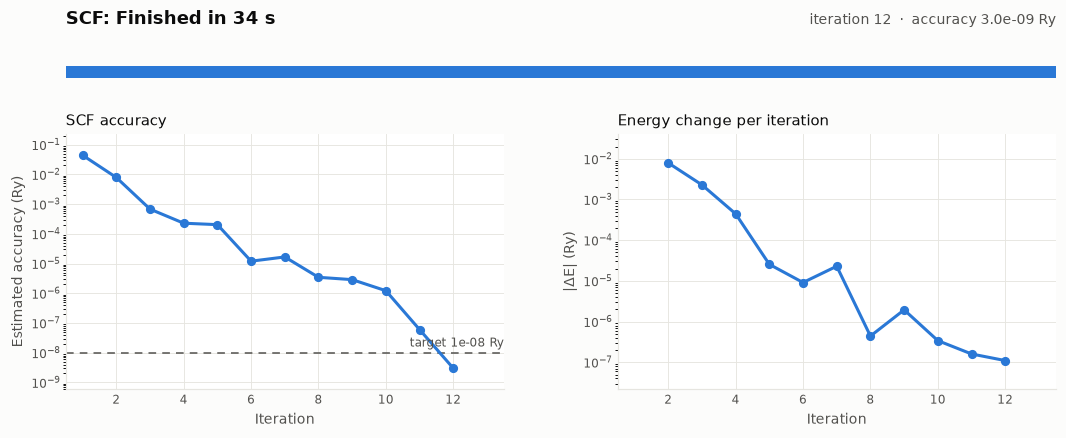

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 34 s
[PASS] SCF converged


In [4]:
# Equivalent of:  pw.x < pw.scf.GaAs.in > pw.scf.GaAs.out, with a live convergence plot
if RECOVER:
    print("RECOVER is on: keeping the existing SCF result, because ph.x restarts from it")
    GAAS_SCF_OUT = (GAAS_RUN / "pw.scf.GaAs.out").read_text(errors="ignore")
else:
    GAAS_SCF_OUT = run_pw("pw.scf.GaAs.in", GAAS_SCF_INPUT, GAAS_RUN)

### 3.2 Dynamical Matrix Calculation (in parallel)

Uses `ph.x` (density functional perturbation theory) to calculate the dynamical matrix at each point of a uniform 4×4×4 q-grid. A quick setup run first lists the q-points. Each q-point then runs as its own `ph.x` process in `runs/ph_gaas_parallel/qN`, up to `PH_WORKERS` at a time. At Γ it also calculates the dielectric tensor and Born effective charges, which give the LO-TO splitting of this polar crystal.

With the tutorial's settings the dielectric constant comes out at about 554, far above the experimental value of about 11, so expect very little LO-TO splitting in the plot.

This is the slow step. To resume after an interruption, see the top of this notebook.

In [5]:
def gaas_ph_input(extra):
    # The tutorial's ph.x input, with the q-grid from section 1 and any extra settings for this run
    return f'''&INPUTPH
  outdir = './tmp/'
  prefix = 'GaAs'
  tr2_ph = 1d-14
  ldisp = .true.
  nq1 = {NQ}
  nq2 = {NQ}
  nq3 = {NQ}
  fildyn = 'GaAs.dyn'
  {extra}
/
'''

In [6]:
# Setup run: start_irr = last_irr = 0 lists the q-points and representations without calculating them.
# It also writes GaAs.dyn0, the q-point list q2r.x needs. It stops early, so it doesn't print JOB DONE.
setup_in = GAAS_RUN / "ph.setup.GaAs.in"
setup_in.write_text(gaas_ph_input("start_irr = 0\n  last_irr = 0"))
with open(setup_in) as fin, open(setup_in.with_suffix(".out"), "w") as fout:
    subprocess.run([PH], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=GAAS_RUN)
setup = setup_in.with_suffix(".out").read_text(errors="ignore")

table = setup.split("Number and degeneracy of irreps per q-point")[-1]
GAAS_IRREPS = {int(n): int(count) for n, count in re.findall(r"^\s*(\d+)(?:\s+-?\d+\.\d+){3}\s+(\d+)\s*$", table, re.M)}
print(f"{len(GAAS_IRREPS)} q-points, {sum(GAAS_IRREPS.values())} representations: {GAAS_IRREPS}")
check("Setup run listed the q-points", len(GAAS_IRREPS) > 0)

8 q-points, 38 representations: {1: 2, 2: 4, 3: 4, 4: 6, 5: 6, 6: 6, 7: 4, 8: 6}
[PASS] Setup run listed the q-points


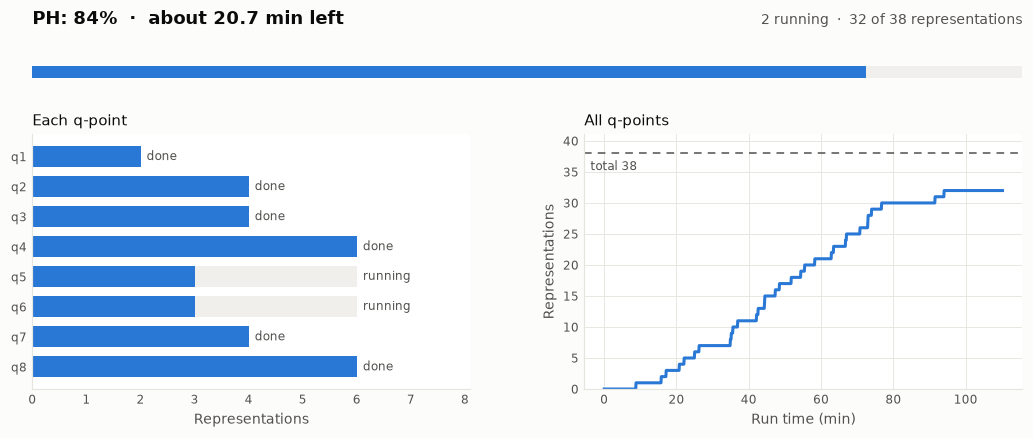

In [ ]:
# Equivalent of running, for each q-point N in its own folder:  ph.x < ph.GaAs.in > ph.GaAs.out
# with start_q = last_q = N in the input, up to PH_WORKERS at a time, with a live progress plot
run_ph_parallel(GAAS_IRREPS, gaas_ph_input, GAAS_RUN, PH_WORKERS)

### 3.3 Real-Space Force Constants

Uses `q2r.x` to inverse Fourier transform the dynamical matrices on the q-grid into interatomic force constants in real space.

In [ ]:
GAAS_Q2R = '''&INPUT
  fildyn = 'GaAs.dyn'
  zasr = 'crystal'
  flfrc = 'GaAs.fc'
/
'''
(GAAS_RUN / "q2r.GaAs.in").write_text(GAAS_Q2R)

# Equivalent of:  q2r.x < q2r.GaAs.in > q2r.GaAs.out
run_qe(Q2R, GAAS_RUN / "q2r.GaAs.in")
check("q2r.x wrote force constants", (GAAS_RUN / "GaAs.fc").exists())

### 3.4 Phonon Frequencies Along the Band Path

Uses `matdyn.x` to Fourier transform the force constants back to a dynamical matrix at any q, and calculates the frequencies along the path L → Γ → X → K → Γ.

In [ ]:
GAAS_MATDYN = '''&INPUT
  asr = 'crystal'
  flfrc = 'GaAs.fc'
  flfrq = 'GaAs.freq'
  flvec = 'GaAs.modes'
  q_in_band_form = .true.
  q_in_cryst_coord = .true.
/
5
0.500 0.500 0.500   20 ! L
0.000 0.000 0.000   20 ! G
0.500 0.000 0.500   20 ! X
0.375 0.375 0.750   20 ! K
0.000 0.000 0.000    1 ! G
'''
(GAAS_RUN / "matdyn.GaAs.in").write_text(GAAS_MATDYN)

# Equivalent of:  matdyn.x < matdyn.GaAs.in > matdyn.GaAs.out
run_qe(MATDYN, GAAS_RUN / "matdyn.GaAs.in")
check("matdyn.x wrote frequencies", (GAAS_RUN / "GaAs.freq.gp").exists())

### 3.5 Plotting the Phonon Dispersion

Plots the six phonon branches along the path. The axis starts at zero as in the tutorial, so the check below reports the lowest frequency, because an imaginary mode (shown as negative) would otherwise be hidden.

In [ ]:
data = np.loadtxt(GAAS_RUN / "GaAs.freq.gp")
check("No imaginary frequencies", data[:, 1:].min() > -5, f"lowest {data[:, 1:].min():.2f} cm-1")

fig, ax = plt.subplots(figsize=(8, 6), dpi=150, facecolor="white")
for band in range(data.shape[1] - 1):
    ax.plot(data[:, 0], data[:, band + 1], linewidth=1, alpha=0.5, color="k")

# High symmetry q-points (check matdyn.GaAs.in)
ticks = [data[0, 0], data[20, 0], data[40, 0], data[60, 0], data[-1, 0]]
for tick in ticks[:-1]:
    ax.axvline(tick, linewidth=0.5, color="k", alpha=0.5)
ax.set_xticks(ticks, labels=["L", r"$\Gamma$", "X", "U,K", r"$\Gamma$"])
ax.set_ylabel("Frequency (cm$^{-1}$)")
ax.set_xlim(data[0, 0], data[-1, 0])
ax.set_ylim(0, )
ax.set_title("GaAs phonon dispersion")
plt.show()

## 4. Phonon Density of States

### 4.1 Phonon DOS Calculation

Reruns `matdyn.x` with `dos = .true.` to calculate the frequencies on a dense 25×25×25 q-grid and count the modes at each frequency, in total and projected onto the Ga and As atoms.

In [ ]:
GAAS_MATDYN_DOS = '''&INPUT
  asr   = 'crystal'
  flfrc = 'GaAs.fc'
  flfrq = 'GaAs.dos.freq'
  flvec = 'GaAs.dos.modes'
  dos   = .true.
  fldos = 'GaAs.dos'
  nk1   = 25
  nk2   = 25
  nk3   = 25
/
'''
(GAAS_RUN / "matdyn.dos.GaAs.in").write_text(GAAS_MATDYN_DOS)

# Equivalent of:  matdyn.x < matdyn.dos.GaAs.in > matdyn.dos.GaAs.out
run_qe(MATDYN, GAAS_RUN / "matdyn.dos.GaAs.in")
check("matdyn.x wrote the DOS", (GAAS_RUN / "GaAs.dos").exists())

### 4.2 Plotting the Phonon DOS

Plots the total phonon DOS with its Ga and As projections.

In [ ]:
freq, dos, pdos_Ga, pdos_As = np.loadtxt(GAAS_RUN / "GaAs.dos", unpack=True)

fig, ax = plt.subplots(figsize=(8, 6), dpi=150, facecolor="white")
ax.plot(freq, dos, c="k", lw=0.5, label="Total")
ax.plot(freq, pdos_Ga, c="b", lw=0.5, label="Ga")
ax.plot(freq, pdos_As, c="r", lw=0.5, label="As")
ax.set_xlabel(r"$\Omega~(cm^{-1}$)")
ax.set_ylabel("Phonon DOS (state/cm$^{-1}/u.c.$)")
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(freq[0], freq[-1])
ax.set_title("GaAs phonon density of states")
plt.show()